# 4. Заряд для разных энергий

Для каждой энергии моделируются 1000 событий. Фотон считается зарегистрированным, если луч от источника пересекает фотокатод на поверхности. Рассеяние и поглощение внутри детектора не учитываются.

Измеряем полный заряд в фотоэлектронах, относительную ширину распределения `σ/μ` и изменение среднего при смещении источника на 1 м по оси `z`. Радиус детектора задан в сантиметрах, поэтому смещение 1 м соответствует `z = 100 см`. При этом среднее значение световыхода практически не изменяется.

С увеличением энергии относительная ширина уменьшается, так как появляется больше фотонов, что уменьшает дисперсию.



In [1]:
import numpy as np
import matplotlib.pyplot as plt


class Detector:
    def __init__(self):
        self.R = 200.0
        self.N = 40
        self.r = 10.0
        self.a = 0.5

    def get_pmt_positions(self):
        from math import acos, cos, pi, sin

        positions = []
        for i in range(self.N):
            phi = acos(1 - 2 * (i + 0.5) / self.N)
            theta = pi * (1 + np.sqrt(5)) * i
            positions.append((
                self.R * cos(theta) * sin(phi),
                self.R * sin(theta) * sin(phi),
                self.R * cos(phi)
            ))
        return positions


class Source:
    def __init__(self, Y=10000):
        self.Y = Y


def simulate_charge_distribution(
    energy,
    source_position,
    detector,
    source,
    rng,
    number_of_events=1000,
    event_batch_size=8
):
    photons_per_event = round(source.Y * energy)
    source_position = np.asarray(source_position, dtype=float)
    source_radius_squared = np.dot(source_position, source_position)
    if source_radius_squared >= detector.R**2:
        raise ValueError("Источник должен находиться внутри детектора")

    pmt_normals = np.asarray(detector.get_pmt_positions()) / detector.R
    projection_threshold = np.sqrt(detector.R**2 - detector.r**2)
    charges = np.empty(number_of_events, dtype=np.int64)

    for batch_start in range(0, number_of_events, event_batch_size):
        batch_end = min(batch_start + event_batch_size, number_of_events)
        batch_events = batch_end - batch_start
        photon_count = batch_events * photons_per_event

        cos_theta = rng.uniform(-1.0, 1.0, photon_count)
        phi = rng.uniform(0.0, 2 * np.pi, photon_count)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        directions = np.column_stack((
            sin_theta * np.cos(phi),
            sin_theta * np.sin(phi),
            cos_theta
        ))

        source_dot_direction = directions @ source_position
        distance_to_boundary = -source_dot_direction + np.sqrt(
            source_dot_direction**2 + detector.R**2 - source_radius_squared
        )
        boundary_points = source_position + distance_to_boundary[:, None] * directions
        projections = boundary_points @ pmt_normals.T
        hits_per_event = np.any(
            projections >= projection_threshold,
            axis=1
        ).reshape(batch_events, photons_per_event).sum(axis=1)

        # Сумма независимых Poisson(a) откликов имеет распределение Poisson(a * hits).
        charges[batch_start:batch_end] = rng.poisson(
            lam=detector.a * hits_per_event
        )

    return charges


detector = Detector()
source = Source()
rng = np.random.default_rng(42)

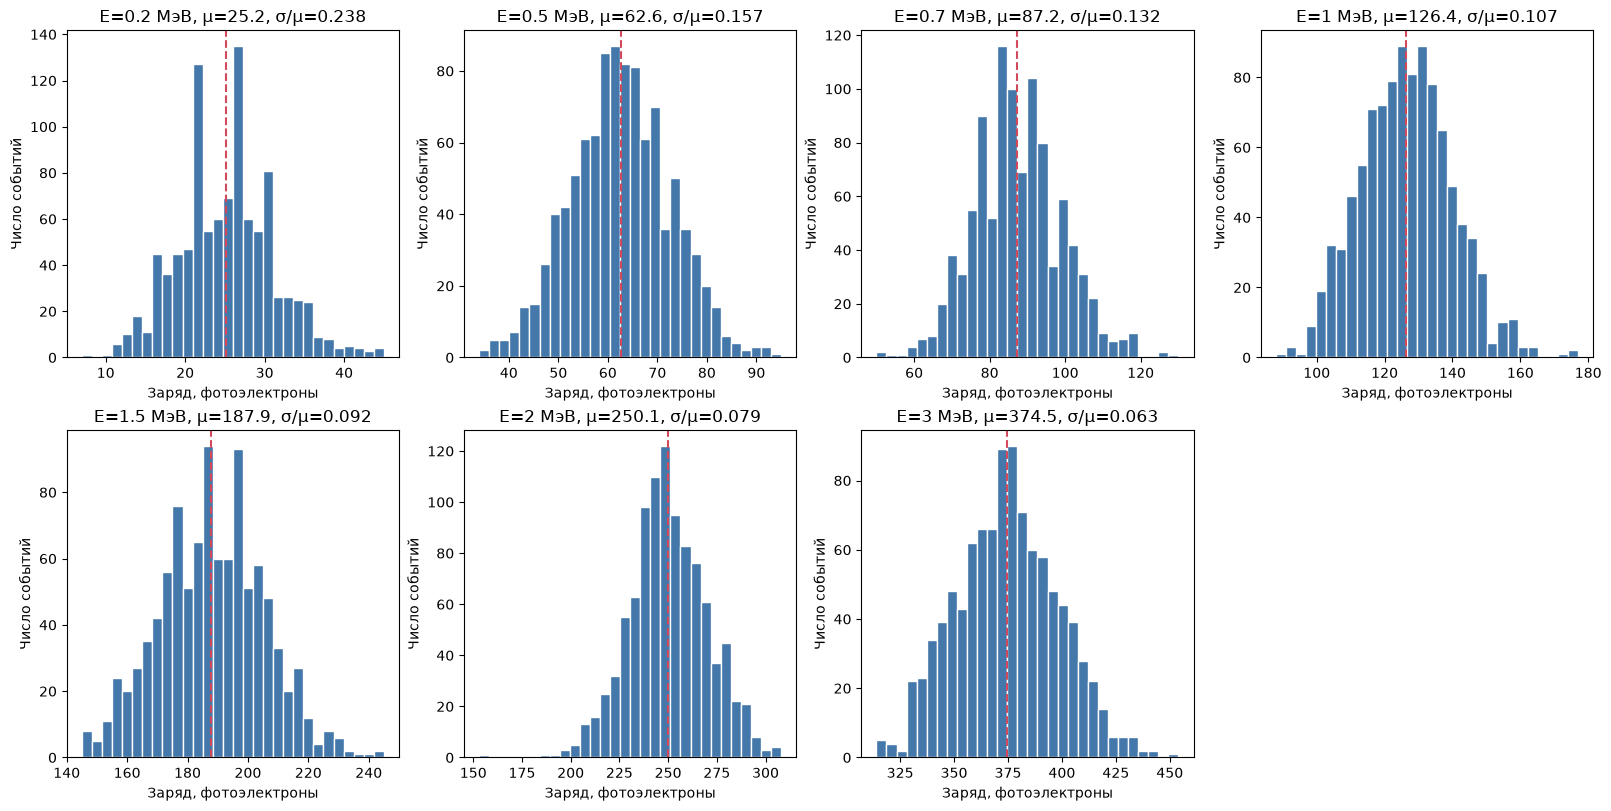

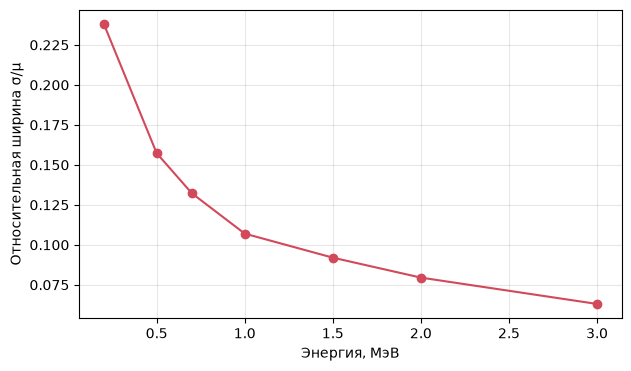

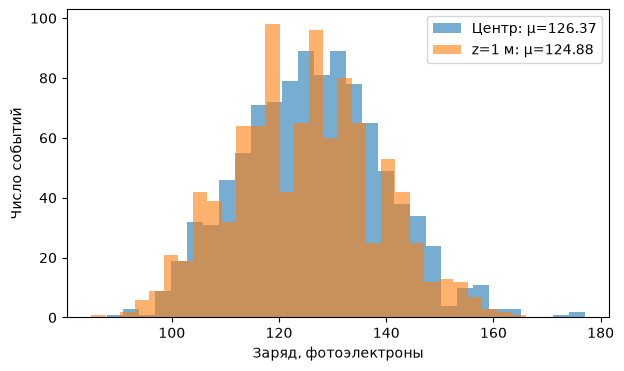

Энергия (МэВ) | Средний заряд | Стандартное отклонение | σ/μ
         0.2 |         25.17 |                   5.99 | 0.2381
         0.5 |         62.61 |                   9.85 | 0.1573
         0.7 |         87.22 |                  11.53 | 0.1322
           1 |        126.37 |                  13.52 | 0.1070
         1.5 |        187.93 |                  17.28 | 0.0920
           2 |        250.05 |                  19.88 | 0.0795
           3 |        374.47 |                  23.60 | 0.0630

1 МэВ: в центре μ=126.37, при z=1 м μ=124.88
Изменение среднего заряда: -1.17%


In [2]:
energies = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]
center_position = (0.0, 0.0, 0.0)
charge_distributions = {
    energy: simulate_charge_distribution(
        energy, center_position, detector, source, rng
    )
    for energy in energies
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
for axis, energy in zip(axes.flat, energies):
    charges = charge_distributions[energy]
    mean_charge = np.mean(charges)
    relative_width = np.std(charges, ddof=1) / mean_charge
    axis.hist(charges, bins=30, color="#4477AA", edgecolor="white")
    axis.axvline(mean_charge, color="#D1495B", linestyle="--")
    axis.set_title(
        f"E={energy:g} МэВ, μ={mean_charge:.1f}, σ/μ={relative_width:.3f}"
    )
    axis.set_xlabel("Заряд, фотоэлектроны")
    axis.set_ylabel("Число событий")
axes.flat[-1].axis("off")
plt.show()

relative_widths = [
    np.std(charge_distributions[energy], ddof=1)
    / np.mean(charge_distributions[energy])
    for energy in energies
]
fig, axis = plt.subplots(figsize=(7, 4))
axis.plot(energies, relative_widths, "o-", color="#D1495B")
axis.set_xlabel("Энергия, МэВ")
axis.set_ylabel("Относительная ширина σ/μ")
axis.grid(True, alpha=0.3)
plt.show()

center_charges = charge_distributions[1.0]
offset_charges = simulate_charge_distribution(
    1.0, (0.0, 0.0, 100.0), detector, source, rng
)
center_mean = np.mean(center_charges)
offset_mean = np.mean(offset_charges)
relative_change = (offset_mean - center_mean) / center_mean * 100

fig, axis = plt.subplots(figsize=(7, 4))
axis.hist(center_charges, bins=30, alpha=0.6, label=f"Центр: μ={center_mean:.2f}")
axis.hist(offset_charges, bins=30, alpha=0.6, label=f"z=1 м: μ={offset_mean:.2f}")
axis.set_xlabel("Заряд, фотоэлектроны")
axis.set_ylabel("Число событий")
axis.legend()
plt.show()

print("Энергия (МэВ) | Средний заряд | Стандартное отклонение | σ/μ")
for energy in energies:
    charges = charge_distributions[energy]
    mean_charge = np.mean(charges)
    std_charge = np.std(charges, ddof=1)
    print(
        f"{energy:>12g} | {mean_charge:>13.2f} | "
        f"{std_charge:>22.2f} | {std_charge / mean_charge:.4f}"
    )
print(
    f"\n1 МэВ: в центре μ={center_mean:.2f}, "
    f"при z=1 м μ={offset_mean:.2f}"
)
print(f"Изменение среднего заряда: {relative_change:+.2f}%")